# Problematic Internet Use: code walkthrough

**Kaggle competition:** Child Mind Institute, Problematic Internet Use (2024)
**Goal:** predict how severe a child's problematic internet use is, on a 0 to 3 scale called
**sii** (Severity Impairment Index), from physical and fitness measurements, questionnaires and
a wrist-worn activity tracker.

In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from scipy.optimize import minimize
from sklearn.metrics import cohen_kappa_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBRegressor

## Paths and settings

In [ ]:
KAGGLE = next((p.parent for p in Path("/kaggle/input").rglob("data_dictionary.csv")), None) if Path("/kaggle/input").exists() else None
if KAGGLE: 
    DATA, OUT = KAGGLE, Path("/kaggle/working")
else:
    ROOT = Path.cwd() 
    DATA, OUT = ROOT / "data", ROOT / "results"
OUT.mkdir(exist_ok=True)
SEEDS = [42, 7, 2024, 11, 99]
N_FOLDS = 5

## The metric and the cut points

In [ ]:
def qwk(y, p):
    return cohen_kappa_score(y, p, weights="quadratic")


def cut(pred, t):
    return np.digitize(pred, np.sort(t))


def fit_thresholds(y, pred):
    x0 = np.quantile(pred, np.cumsum(np.bincount(y, minlength=4))[:3] / len(y))
    best = minimize(lambda t: -qwk(y, cut(pred, t)), x0=x0, method="Nelder-Mead")
    return np.sort(best.x)

## Features from the wrist sensor (actigraphy)

In [ ]:
def series_features(split):
    """One row per child: activity summaries from worn periods of the wrist sensor."""
    cache = OUT / f"series_{split}_features.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    lf = pl.scan_parquet(DATA / f"series_{split}.parquet" / "*" / "*.parquet", hive_partitioning=True)
    worn = lf.filter(pl.col("non-wear_flag") == 0).with_columns(
        hour=(pl.col("time_of_day") / 3.6e12).floor(),
        mag=(pl.col("X") ** 2 + pl.col("Y") ** 2 + pl.col("Z") ** 2).sqrt(),
    )
    night = (pl.col("hour") < 6) | (pl.col("hour") >= 22)
    agg = []
    for c in ["enmo", "anglez", "light", "mag"]:
        agg += [pl.col(c).mean().alias(f"{c}_mean"), pl.col(c).std().alias(f"{c}_std"),
                pl.col(c).quantile(0.9).alias(f"{c}_q90"), pl.col(c).median().alias(f"{c}_median")]
    agg += [
        pl.col("enmo").filter(night).mean().alias("enmo_night_mean"),
        pl.col("enmo").filter(~night).mean().alias("enmo_day_mean"),
        pl.col("light").filter(night).mean().alias("light_night_mean"),
        (pl.col("enmo") > 0.1).mean().alias("active_frac"),
        (pl.col("enmo") < 0.01).mean().alias("still_frac"),
        pl.col("relative_date_PCIAT").n_unique().alias("n_days_worn"),
        pl.len().alias("n_worn_samples"),
    ]
    feats = worn.group_by("id").agg(agg).collect().to_pandas()
    wear = lf.group_by("id").agg(pl.col("non-wear_flag").mean().alias("nonwear_frac")).collect().to_pandas()
    feats = feats.merge(wear, on="id", how="outer")
    feats["enmo_night_day_ratio"] = feats["enmo_night_mean"] / (feats["enmo_day_mean"] + 1e-6)
    feats.to_parquet(cache)
    return feats

## Tabular features

In [ ]:
def tabular(df):
    df = df.copy()
    for c in [c for c in df.columns if c.endswith("Season")]:
        df[c] = df[c].map({"Spring": 0, "Summer": 1, "Fall": 2, "Winter": 3})
    df["BMI_Age"] = df["Physical-BMI"] * df["Basic_Demos-Age"]
    df["Internet_Hours_Age"] = df["PreInt_EduHx-computerinternet_hoursday"] * df["Basic_Demos-Age"]
    df["BFP_BMI"] = df["BIA-BIA_Fat"] / df["BIA-BIA_BMI"]
    df["FFMI_BFP"] = df["BIA-BIA_FFMI"] / df["BIA-BIA_Fat"]
    df["Height_Age"] = df["Physical-Height"] / df["Basic_Demos-Age"]
    return df

## The three models and the two targets



In [ ]:
def models(seed, target="sii"):
    """target="sii": plain regression on the 0-3 index.
    target="total": Tweedie regression on the 0-100 PCIAT total score (zero-heavy, skewed),
    a finer-grained signal than the four classes."""
    tw = target == "total"
    return {
        "lgbm": LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=30,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=5,
                              objective="tweedie" if tw else "regression", random_state=seed, verbose=-1),
        "xgb": XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=4, subsample=0.8,
                            colsample_bytree=0.6, reg_lambda=5, objective="reg:tweedie" if tw else "reg:squarederror",
                            random_state=seed, tree_method="hist"),
        "cat": CatBoostRegressor(iterations=400, learning_rate=0.04, depth=5, l2_leaf_reg=8,
                                 loss_function="Tweedie:variance_power=1.5" if tw else "RMSE", random_seed=seed, verbose=0),
    }

## Cross-validation


In [ ]:
def cross_validate(X, y, Xte, target_values=None, target="sii"):
    """Folds are always stratified on sii; the model is fitted on target_values (sii or PCIAT total)."""
    t = y if target_values is None else target_values
    oof = {m: np.zeros(len(X)) for m in ["lgbm", "xgb", "cat"]}
    test = {m: np.zeros(len(Xte)) for m in oof}
    for seed in SEEDS:
        for tr, va in StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed).split(X, y):
            for name, m in models(seed, target).items():
                m.fit(X.iloc[tr], t[tr])
                oof[name][va] += m.predict(X.iloc[va]) / len(SEEDS)
                test[name] += m.predict(Xte) / (len(SEEDS) * N_FOLDS)
    return oof, test

## Honest scoring with nested thresholds

In [ ]:
def honest_qwk(y, pred, seed=0):
    """Thresholds fitted on 4/5 of the out-of-fold predictions, scored on the held-out 1/5."""
    out = np.zeros(len(y), dtype=int)
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=seed).split(pred, y):
        out[va] = cut(pred[va], fit_thresholds(y[tr], pred[tr]))
    return qwk(y, out)

## Main: load data and build the two feature sets


In [ ]:
def main():
    train = pd.read_csv(DATA / "train.csv")
    test = pd.read_csv(DATA / "test.csv")
    train = train[train["sii"].notna()].reset_index(drop=True)
    y = train["sii"].astype(int).to_numpy()
    total = train["PCIAT-PCIAT_Total"].to_numpy(dtype=float)

    base_cols = [c for c in test.columns if c != "id"]  # PCIAT answers are train-only (they define sii)
    Xtr_tab, Xte_tab = tabular(train[["id"] + base_cols]), tabular(test[["id"] + base_cols])
    Xtr_full = Xtr_tab.merge(series_features("train"), on="id", how="left")
    Xte_full = Xte_tab.merge(series_features("test"), on="id", how="left")
    Xte_full = Xte_full.reindex(columns=Xtr_full.columns)

## Main: run both feature sets and blend the two targets

In [ ]:
    report = {"n_children": int(len(y)), "class_counts": {int(k): int(v) for k, v in zip(*np.unique(y, return_counts=True))},
              "cv": f"{N_FOLDS}-fold stratified x {len(SEEDS)} seeds"}
    for tag, Xa, Xb in [("tabular_only", Xtr_tab, Xte_tab), ("tabular_plus_actigraphy", Xtr_full, Xte_full)]:
        Xa, Xb = Xa.drop(columns="id"), Xb.drop(columns="id")
        oof, te = cross_validate(Xa, y, Xb)
        oof_t, te_t = cross_validate(Xa, y, Xb, total, target="total")
        z = lambda a, ref: (a - ref.mean()) / ref.std()
        s_sii, s_tot = np.mean([oof[m] for m in oof], axis=0), np.mean([oof_t[m] for m in oof_t], axis=0)
        blend = 0.5 * z(s_sii, s_sii) + 0.5 * z(s_tot, s_tot)  # standardise each, then average
        report.setdefault("targets", {})[tag] = {
            "qwk_sii_model_nested": round(np.mean([honest_qwk(y, s_sii, k) for k in range(5)]), 4),
            "qwk_total_model_nested": round(np.mean([honest_qwk(y, s_tot, k) for k in range(5)]), 4),
        }
        t_sii, t_tot = np.mean([te[m] for m in te], axis=0), np.mean([te_t[m] for m in te_t], axis=0)
        te = {"blend": 0.5 * z(t_sii, s_sii) + 0.5 * z(t_tot, s_tot)}
        t = fit_thresholds(y, blend)
        report[tag] = {
            "n_features": Xa.shape[1],
            **{f"qwk_sii_{m}": round(qwk(y, cut(oof[m], fit_thresholds(y, oof[m]))), 4) for m in oof},
            "qwk_blend_tuned_on_oof": round(qwk(y, cut(blend, t)), 4),
            "qwk_blend_nested_thresholds": round(np.mean([honest_qwk(y, blend, s) for s in range(5)]), 4),
            "thresholds_on_standardised_blend": [round(float(v), 3) for v in t],
        }
        print(tag, json.dumps(report[tag]))

## Main: save predictions and feature importance


In [ ]:
        if tag == "tabular_plus_actigraphy":
            pred_cls = cut(blend, t)
            report["confusion_matrix"] = confusion_matrix(y, pred_cls).tolist()
            test_blend = te["blend"]
            pd.DataFrame({"id": test["id"], "sii": cut(test_blend, t)}).to_csv(OUT / "submission.csv", index=False)
            fi = LGBMRegressor(**models(42)["lgbm"].get_params()).fit(Xa, y)
            imp = pd.Series(fi.booster_.feature_importance("gain"), index=Xa.columns).sort_values(ascending=False)
            imp.head(25).to_csv(OUT / "feature_importance_top25.csv")
            np.save(OUT / "oof_blend.npy", blend)
            Xa.to_parquet(OUT / "X_train_full.parquet")

In [ ]:
    (OUT / "metrics.json").write_text(json.dumps(report, indent=2))
    print(json.dumps(report, indent=2))


if __name__ == "__main__":
    main()

## Results


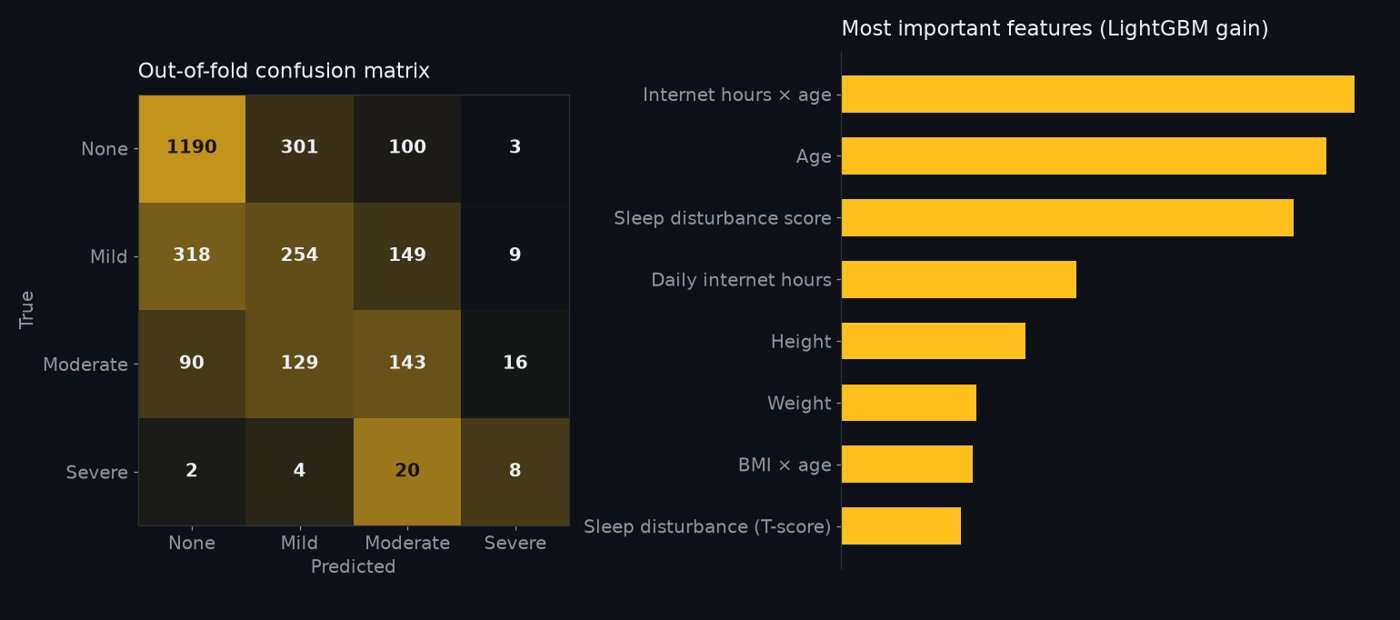

*Out-of-fold confusion matrix and the most important features*